# Constant correlation : A first implementation

**Question.** For a worst-of / best-of on a basket of two or three stocks, a constant correlation is the simplest input of
the pricer. Is the correlation realised over the life of the product well approximated by a constant, for maturities
from 1 month to 5 years ?

**Data.** Daily log returns (adjusted close) of 23 large caps of Euronext Paris, 2005 → today
(`Data/Equity/download_universe.py`). All the stocks close at the same time on the same exchange : daily returns are
synchronous. 20 baskets : 13 of two stocks and 7 of three, 13 within a sector and 7 across sectors.

**Method** (`constant_correlation.py`). For each basket, each pair and each horizon H ∈ {1m, 2m, 3m, 6m, 1y, 2y, 3y, 5y}
(21 to 1260 trading days), the realised correlation over windows of H days (one window every 21 days) is compared with

- the **in-sample constant** : the full-sample correlation (the best a constant can do, with hindsight) ;
- the **out-of-sample constant** : the correlation of all the returns before the window starts (expanding window, at
  least 2 years), i.e. the constant a pricer could actually have used.

The RMSE alone does not answer the question : even with a truly constant correlation, the correlation realised over
H days is a noisy estimate (≈ (1 − ρ²)/√H for i.i.d. Gaussian returns, more with fat tails). Every statistic is
therefore compared with its distribution **under H0 : constant conditional correlation**, simulated 1000 times per
basket by a filtered bootstrap : a GARCH(1,1)-t per stock, the vectors of standardised residuals resampled i.i.d. and
rescaled by the observed volatilities. The simulated stocks have the same fat tails and the same volatility history
as the real ones, but a dependence that does not change over time.

**Tests.**
1. Monte Carlo test on the RMSE (in- and out-of-sample) : p = P_H0(RMSE ≥ observed RMSE).
2. Fisher z homogeneity test on the ⌊T/H⌋ non-overlapping windows : asymptotic χ² p-value, and Monte Carlo p-value.
3. Multivariate Engle-Sheppard (2001) test of constant conditional correlation on the daily GARCH residuals.
4. Benjamini-Hochberg correction for the 20 baskets tested at each horizon, and a check of the size of the Monte Carlo
   tests on simulated data where H0 is true.

In [1]:
import os, sys, warnings
sys.path.append(os.path.abspath("."))                                   # Models/Correlation : constant_correlation.py
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import constant_correlation as cc

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
DATA = os.path.join("..", "..", "Data", "Equity")
N_SIMS = 1000
HORIZONS = cc.HORIZONS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.figsize": (11, 4), "lines.linewidth": 1.2})

## 1. Data and baskets

In [2]:
px = pd.read_csv(os.path.join(DATA, "Universe_Daily_AdjClose.csv"), index_col="Date", parse_dates=True)
with open(os.path.join(DATA, "LAST_DOWNLOAD_UNIVERSE.txt")) as f:
    print("downloaded on", f.read().strip(), "-", px.shape[1], "stocks,", f"{px.index[0].date()} -> {px.index[-1].date()}")

rows = {}
for name, basket in cc.BASKETS.items():
    r = cc.basket_returns(px, basket)
    rho = r.corr().values[np.triu_indices(len(basket), 1)]
    rows[name] = {"stocks": len(basket), "start": r.index[0].date(), "days": len(r),
                  "rho min": rho.min(), "rho max": rho.max()}
baskets = pd.DataFrame(rows).T
baskets

downloaded on 2026-11-28 - 23 stocks, 2005-01-03 -> 2026-11-27


,stocks,start,days,rho min,rho max
LVMH / Hermès,2,2005-01-04,5608,0.6059,0.6059
LVMH / Kering,2,2005-01-04,5608,0.7131,0.7131
LVMH / Hermès / Kering,3,2005-01-04,5608,0.509,0.7131
BNP / SocGen,2,2005-01-04,5608,0.8297,0.8297
BNP / SocGen / Crédit Agricole,3,2005-01-04,5608,0.8135,0.8297
Airbus / Safran,2,2005-01-04,5608,0.6472,0.6472
Airbus / Safran / Thales,3,2005-01-04,5608,0.4848,0.6472
L'Oréal / Danone,2,2005-01-04,5608,0.522,0.522
L'Oréal / Pernod,2,2005-01-04,5608,0.5166,0.5166
Vinci / Bouygues / Saint-Gobain,3,2005-01-04,5608,0.6169,0.7015


## 2. Realised correlation by horizon

Correlation realised over the last H days, against the full-sample constant. Over 1 month it is mostly noise ; over
1 to 5 years the noise is small, and what is left is the slow movement of the correlation itself.

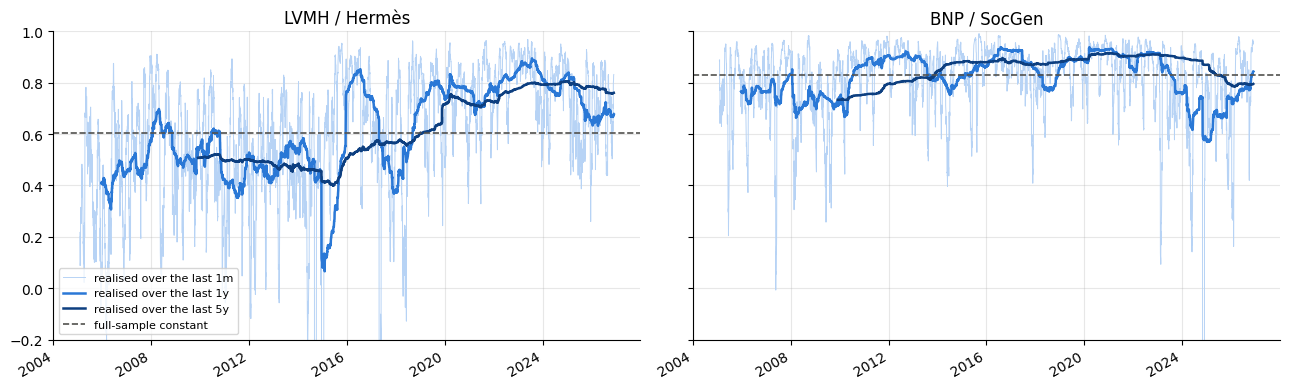

In [3]:
SHADES = {"1m": "#b7d3f5", "1y": "#2a78d6", "5y": "#0d3f80"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for k, name in enumerate(["LVMH / Hermès", "BNP / SocGen"]):
    r = cc.basket_returns(px, cc.BASKETS[name])
    for h, c in SHADES.items():
        cc.realised_correlation(r, HORIZONS[h]).iloc[:, 0].plot(ax=ax[k], color=c, lw=0.7 if h == "1m" else 1.8,
                                                              label=f"realised over the last {h}")
    ax[k].axhline(r.corr().iloc[0, 1], color="#52514e", ls="--", lw=1.2, label="full-sample constant")
    ax[k].set_title(name); ax[k].set_ylim(-0.2, 1); ax[k].set_xlabel("")
ax[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 3. Simulation of H0 and computation of the statistics

1000 H0 paths per basket, the same length as the data (≈ 15 s for the 20 baskets).

In [4]:
results = cc.analyse_all(px, n_sims=N_SIMS, verbose=False)
B = cc.stack(results, "basket")                                        # one row per basket and horizon
P = cc.stack(results, "pairs")                                         # one row per pair and horizon
PU = P.drop_duplicates(["pair", "H"])                                  # pairs present in several baskets once

def table(df, column, index="basket"):
    return df.pivot(index=index, columns="horizon", values=column)[list(HORIZONS)].reindex(
        list(cc.BASKETS) if index == "basket" else None)

B.groupby("horizon", sort=False)[["K", "n_windows", "n_windows_oos"]].first().T.rename(
    index={"K": "non-overlapping windows (Fisher)", "n_windows": "windows (in-sample RMSE)",
           "n_windows_oos": "windows (out-of-sample RMSE)"})

horizon,1m,2m,3m,6m,1y,2y,3y,5y
non-overlapping windows (Fisher),267,133,89,44,22,11,7,4
windows (in-sample RMSE),267,266,265,262,256,244,232,208
windows (out-of-sample RMSE),243,242,241,238,232,220,208,184


## 4. RMSE of a constant correlation

RMSE between the realised correlation of each pair and the constant, pooled over the pairs of the basket. Next to
it, the median RMSE that the same basket would have if its correlation were constant (H0).

In [5]:
rmse_is = table(B, "rmse_is")
display(rmse_is.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.35)
        .set_caption("In-sample RMSE (constant = full-sample correlation)"))
display(table(B, "rmse_is H0 median").style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.35)
        .set_caption("Median in-sample RMSE under H0 (constant correlation) : pure estimation noise"))

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.246,0.215,0.202,0.185,0.169,0.147,0.138,0.132
LVMH / Kering,0.188,0.161,0.149,0.125,0.100,0.071,0.053,0.041
LVMH / Hermès / Kering,0.230,0.197,0.184,0.162,0.142,0.120,0.109,0.102
BNP / SocGen,0.163,0.132,0.123,0.099,0.084,0.078,0.073,0.058
BNP / SocGen / Crédit Agricole,0.174,0.145,0.130,0.105,0.090,0.078,0.066,0.050
Airbus / Safran,0.225,0.186,0.170,0.147,0.136,0.127,0.119,0.119
Airbus / Safran / Thales,0.250,0.206,0.189,0.159,0.141,0.120,0.106,0.093
L'Oréal / Danone,0.251,0.210,0.193,0.176,0.166,0.154,0.146,0.127
L'Oréal / Pernod,0.230,0.188,0.168,0.144,0.132,0.114,0.100,0.089


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.185,0.140,0.118,0.088,0.066,0.048,0.039,0.029
LVMH / Kering,0.155,0.117,0.099,0.074,0.055,0.040,0.032,0.024
LVMH / Hermès / Kering,0.185,0.140,0.120,0.090,0.068,0.050,0.041,0.030
BNP / SocGen,0.129,0.106,0.094,0.076,0.058,0.043,0.035,0.026
BNP / SocGen / Crédit Agricole,0.133,0.105,0.091,0.072,0.055,0.042,0.035,0.026
Airbus / Safran,0.176,0.130,0.110,0.083,0.063,0.047,0.039,0.030
Airbus / Safran / Thales,0.201,0.148,0.124,0.092,0.069,0.051,0.043,0.033
L'Oréal / Danone,0.204,0.148,0.122,0.088,0.063,0.045,0.036,0.026
L'Oréal / Pernod,0.193,0.139,0.115,0.085,0.062,0.045,0.036,0.027


In [6]:
rmse_oos = table(B, "rmse_oos")
display(rmse_oos.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.35)
        .set_caption("Out-of-sample RMSE (constant = correlation of the returns known before the window)"))

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.248,0.222,0.211,0.199,0.188,0.174,0.175,0.182
LVMH / Kering,0.168,0.142,0.131,0.115,0.103,0.087,0.077,0.073
LVMH / Hermès / Kering,0.223,0.195,0.183,0.166,0.155,0.142,0.140,0.144
BNP / SocGen,0.170,0.139,0.132,0.108,0.096,0.094,0.092,0.089
BNP / SocGen / Crédit Agricole,0.166,0.136,0.123,0.102,0.092,0.089,0.087,0.088
Airbus / Safran,0.210,0.172,0.155,0.139,0.140,0.153,0.164,0.188
Airbus / Safran / Thales,0.248,0.205,0.190,0.164,0.154,0.146,0.138,0.138
L'Oréal / Danone,0.256,0.216,0.200,0.186,0.180,0.175,0.170,0.156
L'Oréal / Pernod,0.217,0.178,0.164,0.148,0.145,0.144,0.148,0.157


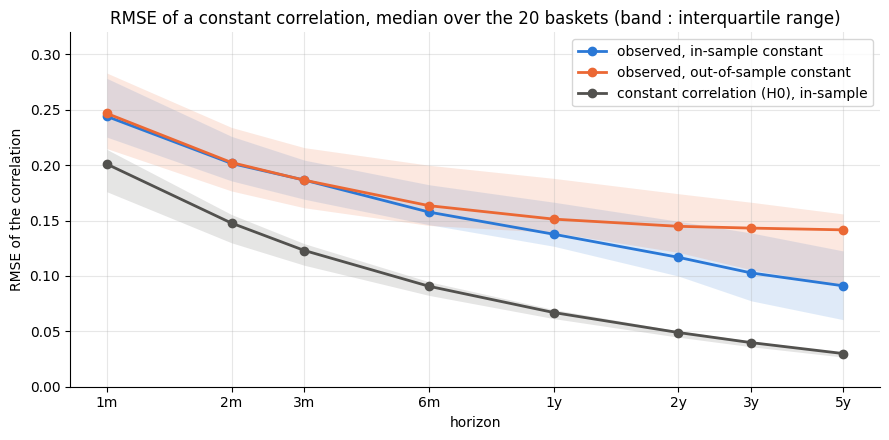

In [7]:
x = np.array(list(HORIZONS.values())) / 252
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c, label in [("rmse_is", "#2a78d6", "observed, in-sample constant"),
                      ("rmse_oos", "#eb6834", "observed, out-of-sample constant"),
                      ("rmse_is H0 median", "#52514e", "constant correlation (H0), in-sample")]:
    t = table(B, col)
    ax.plot(x, t.median(), "o-", color=c, lw=2, ms=6, label=label)
    ax.fill_between(x, t.quantile(0.25), t.quantile(0.75), color=c, alpha=0.15, lw=0)
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels(list(HORIZONS)); ax.minorticks_off()
ax.set_xlabel("horizon"); ax.set_ylabel("RMSE of the correlation"); ax.set_ylim(0, 0.32)
ax.set_title("RMSE of a constant correlation, median over the 20 baskets (band : interquartile range)")
ax.legend(); plt.tight_layout(); plt.show()

**Which part of the error is due to the correlation moving ?** Under H0 the squared RMSE is pure estimation
noise. The *excess RMSE* √max(RMSE² − E_H0[RMSE²], 0) is the part that a constant correlation cannot explain : the
typical size of the actual variations of the correlation at that horizon.

In [8]:
excess = {"in-sample": table(B, "rmse_is excess"), "out-of-sample": table(B, "rmse_oos excess")}
for k, t in excess.items():
    display(t.style.format("{:.3f}").background_gradient(cmap="Blues", axis=None, vmin=0, vmax=0.25)
            .set_caption(f"Excess RMSE, {k} constant"))
pd.DataFrame({f"{k}, median": t.median() for k, t in excess.items()} |
             {f"{k}, min": t.min() for k, t in excess.items()}).T

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.160,0.161,0.162,0.161,0.154,0.138,0.131,0.128
LVMH / Kering,0.105,0.111,0.110,0.100,0.083,0.058,0.040,0.031
LVMH / Hermès / Kering,0.135,0.138,0.139,0.133,0.124,0.108,0.100,0.097
BNP / SocGen,0.094,0.071,0.070,0.050,0.046,0.054,0.052,0.042
BNP / SocGen / Crédit Agricole,0.109,0.099,0.090,0.074,0.068,0.062,0.053,0.040
Airbus / Safran,0.140,0.132,0.129,0.121,0.120,0.117,0.111,0.113
Airbus / Safran / Thales,0.148,0.143,0.142,0.128,0.122,0.108,0.096,0.086
L'Oréal / Danone,0.147,0.149,0.149,0.152,0.153,0.147,0.141,0.124
L'Oréal / Pernod,0.123,0.126,0.121,0.116,0.116,0.104,0.092,0.084


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.160,0.168,0.170,0.174,0.172,0.163,0.167,0.175
LVMH / Kering,0.057,0.076,0.082,0.083,0.082,0.072,0.062,0.062
LVMH / Hermès / Kering,0.119,0.131,0.134,0.134,0.134,0.127,0.129,0.135
BNP / SocGen,0.101,0.077,0.078,0.058,0.054,0.063,0.065,0.065
BNP / SocGen / Crédit Agricole,0.094,0.081,0.076,0.064,0.064,0.070,0.071,0.075
Airbus / Safran,0.111,0.108,0.106,0.108,0.121,0.141,0.155,0.181
Airbus / Safran / Thales,0.142,0.139,0.140,0.132,0.134,0.132,0.127,0.128
L'Oréal / Danone,0.152,0.155,0.156,0.161,0.166,0.166,0.163,0.150
L'Oréal / Pernod,0.093,0.107,0.112,0.117,0.127,0.133,0.139,0.151


horizon,1m,2m,3m,6m,1y,2y,3y,5y
"in-sample, median",0.1441,0.1404,0.1398,0.1283,0.121,0.1057,0.09386,0.08496
"out-of-sample, median",0.1377,0.1351,0.1372,0.1301,0.1323,0.1323,0.1322,0.1315
"in-sample, min",0.09448,0.07101,0.07003,0.0496,0.04619,0.05352,0.04026,0.03086
"out-of-sample, min",0.05715,0.07355,0.07304,0.05756,0.0536,0.0626,0.06235,0.05656


## 5. Tests

### 5.1 Monte Carlo tests

p-values of the RMSE (in- and out-of-sample) and of the Fisher homogeneity statistic against their distributions
under H0. With 1000 simulations the smallest possible p-value is 1/1001 ≈ 0.001 (no simulation as extreme as the
data). At each horizon, the 20 p-values are corrected by Benjamini-Hochberg (false discovery rate 5 %).

In [9]:
TESTS = {"RMSE in-sample": "rmse_is p MC", "RMSE out-of-sample": "rmse_oos p MC", "Fisher Q": "Q p MC"}
for k, col in TESTS.items():
    display(table(B, col).style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=None, vmin=0, vmax=0.2)
            .set_caption(f"Monte Carlo p-value, {k}"))

horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
LVMH / Kering,0.003,0.001,0.001,0.001,0.001,0.001,0.025,0.060
LVMH / Hermès / Kering,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
BNP / SocGen,0.091,0.183,0.178,0.231,0.193,0.114,0.101,0.109
BNP / SocGen / Crédit Agricole,0.002,0.004,0.010,0.022,0.025,0.031,0.041,0.055
Airbus / Safran,0.001,0.001,0.001,0.001,0.001,0.002,0.003,0.002
Airbus / Safran / Thales,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Danone,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Pernod,0.002,0.001,0.001,0.001,0.001,0.001,0.001,0.001


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
LVMH / Kering,0.161,0.024,0.010,0.004,0.003,0.013,0.020,0.024
LVMH / Hermès / Kering,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
BNP / SocGen,0.090,0.171,0.167,0.198,0.169,0.118,0.108,0.103
BNP / SocGen / Crédit Agricole,0.014,0.032,0.035,0.062,0.058,0.041,0.035,0.031
Airbus / Safran,0.004,0.003,0.002,0.002,0.002,0.002,0.001,0.001
Airbus / Safran / Thales,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Danone,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Pernod,0.031,0.005,0.003,0.001,0.001,0.001,0.001,0.001


horizon,1m,2m,3m,6m,1y,2y,3y,5y
basket,,,,,,,,
LVMH / Hermès,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
LVMH / Kering,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.040
LVMH / Hermès / Kering,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
BNP / SocGen,0.001,0.001,0.001,0.001,0.008,0.013,0.037,0.045
BNP / SocGen / Crédit Agricole,0.001,0.001,0.001,0.001,0.001,0.001,0.007,0.010
Airbus / Safran,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
Airbus / Safran / Thales,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Danone,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001
L'Oréal / Pernod,0.001,0.001,0.001,0.001,0.001,0.001,0.001,0.001


In [10]:
rejected = {}
for k, col in TESTS.items():
    t = table(B, col)
    rejected[k] = t.apply(lambda p: (cc.benjamini_hochberg(p) < 0.05).sum())
rejected = pd.DataFrame(rejected).T
rejected.columns.name = "horizon"
print("Number of baskets (out of 20) where a constant correlation is rejected at 5 %, after Benjamini-Hochberg :")
rejected

Number of baskets (out of 20) where a constant correlation is rejected at 5 %, after Benjamini-Hochberg :


horizon,1m,2m,3m,6m,1y,2y,3y,5y
RMSE in-sample,19,19,19,19,19,19,19,17
RMSE out-of-sample,18,19,19,18,18,19,19,19
Fisher Q,20,20,20,20,20,20,20,18


### 5.2 The asymptotic Fisher test is not valid here

The usual test of equal correlations across sub-periods takes var(z) = 1/(H − 3) for the Fisher z of each window,
which holds for i.i.d. Gaussian returns. With fat tails and moving volatilities the realised correlation is noisier,
so the χ² test rejects a constant correlation even when it is true. Its rejection rate on the H0 simulations
(nominal 5 %) :

In [11]:
size = PU.pivot_table(index="pair", columns="horizon", values="Q asymptotic size under H0")[list(HORIZONS)]
display(size.describe().loc[["mean", "min", "max"]].style.format("{:.0%}")
        .set_caption(f"Rejection rate at 5 % of the asymptotic Fisher test when H0 is true (over the {size.shape[0]} distinct pairs)"))
# check on i.i.d. Gaussian returns, where the chi2 approximation is right
G = np.random.default_rng(0).multivariate_normal([0, 0], [[1, 0.6], [0.6, 1]], (500, len(px)))
st = cc.constancy_statistics(G, list(HORIZONS.values()))
print("i.i.d. Gaussian returns :", {h: f"{np.mean(stats.chi2.sf(st[H]['Q'][:, 0], st[H]['K'] - 1) < 0.05):.0%}"
                                    for h, H in HORIZONS.items()})

horizon,1m,2m,3m,6m,1y,2y,3y,5y
mean,99%,97%,96%,88%,78%,67%,60%,47%
min,94%,87%,82%,68%,57%,47%,41%,31%
max,100%,100%,100%,100%,100%,98%,95%,86%


i.i.d. Gaussian returns : {'1m': '4%', '2m': '5%', '3m': '5%', '6m': '5%', '1y': '4%', '2y': '5%', '3y': '5%', '5y': '5%'}


The asymptotic p-values (below) are therefore not evidence by themselves ; the Monte Carlo p-values of 5.1,
computed against simulations with the same fat tails and volatilities, are.

In [12]:
table(PU, "Q p asymptotic", index="pair").style.format("{:.1e}").set_caption("Asymptotic Fisher p-value, per pair")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
pair,,,,,,,,
AIRBUS/LVMH,6.9e-18,2.4e-24,4.1e-26,7.1e-28,1.2e-23,1.2e-23,1.0e-13,2.6e-06
AIRBUS/SAFRAN,1.2e-40,7.7e-48,2.2e-51,6.4e-51,5.4e-57,2.1e-61,6.3e-56,3.6e-40
AIRBUS/THALES,1.3e-25,1.1e-31,1.1e-33,2.0e-41,4.3e-41,2.2e-31,2.3e-26,1.1e-30
AIRLIQUIDE/CAPGEMINI,6.8e-30,1.9e-26,1.3e-23,7.0e-26,4.6e-24,2.5e-20,9.4e-18,1.6e-12
BNP/AIRBUS,3.2e-24,1.0e-31,1.3e-27,1.5e-22,2.3e-22,9.3e-24,3.1e-18,2.7e-09
BNP/CREDITAGRICOLE,1.4e-65,1.0e-74,5.7e-62,2.2e-50,1.1e-46,4.8e-46,9.2e-28,1.2e-20
BNP/LVMH,2.7e-20,1.1e-22,3.5e-26,2.6e-27,3.3e-21,9.6e-15,1.4e-10,2.2e-07
BNP/SOCGEN,2.8e-69,1.1e-79,2.1e-72,2.4e-71,4.3e-67,7.9e-64,2.5e-51,3.6e-36
BOUYGUES/SAINTGOBAIN,9.6e-19,2.5e-19,4.8e-31,1.1e-28,8.1e-24,2.9e-26,6.3e-23,5.4e-19


### 5.3 Engle-Sheppard test on daily conditional correlations

A different alternative : the daily conditional correlation of the GARCH residuals follows an autoregression
(DCC-like dynamics). The test regresses the cross products of the whitened residuals on their own lags.

In [13]:
es = pd.DataFrame({k: v["engle_sheppard"]["p-value"] for k, v in results.items()}).T
es.columns = [f"{s} lags" for s in es.columns]
display(es.style.format("{:.4f}").background_gradient(cmap="Blues_r", axis=None, vmin=0, vmax=0.2)
        .set_caption("Engle-Sheppard p-value"))
print("rejected at 5 % after Benjamini-Hochberg :", {c: int((cc.benjamini_hochberg(es[c]) < 0.05).sum()) for c in es})

,1 lags,5 lags,10 lags
LVMH / Hermès,0.0000,0.0000,0.0000
LVMH / Kering,0.0981,0.0475,0.1114
LVMH / Hermès / Kering,0.0000,0.0001,0.0006
BNP / SocGen,0.7563,0.3052,0.5572
BNP / SocGen / Crédit Agricole,0.9399,0.5840,0.2500
Airbus / Safran,0.7412,0.6027,0.9050
Airbus / Safran / Thales,0.2621,0.0022,0.0049
L'Oréal / Danone,0.3089,0.2515,0.0000
L'Oréal / Pernod,0.7534,0.9289,0.8837
Vinci / Bouygues / Saint-Gobain,0.0003,0.0001,0.0001


rejected at 5 % after Benjamini-Hochberg : {'1 lags': 4, '5 lags': 11, '10 lags': 12}


### 5.4 Size of the Monte Carlo tests

The Monte Carlo tests are valid only if they do not reject when H0 is true. Check : 40 artificial LVMH / Hermès
histories simulated under H0 are put through the whole procedure (GARCH fit, 200 simulations, tests) ; the rejection
rate at 5 % should be at most 5 %.

In [14]:
r = cc.basket_returns(px, cc.BASKETS["LVMH / Hermès"])
params, resid, vol = cc.fit_garch(r)
rng, pvalues = np.random.default_rng(1), []
for k in range(40):
    fake = pd.DataFrame(cc.simulate_h0(params, resid, vol, 1, rng)[0] / 100, index=r.index, columns=r.columns)
    pvalues.append(cc.analyse_basket(fake, n_sims=200, seed=100 + k)["basket"].set_index("horizon")[list(TESTS.values())])
size_mc = (pd.concat(pvalues) < 0.05).groupby(level=0).mean().reindex(list(HORIZONS)).set_axis(list(TESTS), axis=1).T
size_mc.style.format("{:.0%}").set_caption("Rejection rate at 5 % under H0 (40 artificial histories)")

horizon,1m,2m,3m,6m,1y,2y,3y,5y
RMSE in-sample,0%,0%,0%,0%,0%,2%,5%,5%
RMSE out-of-sample,0%,0%,0%,2%,2%,2%,2%,5%
Fisher Q,0%,0%,2%,2%,8%,5%,5%,2%


## 6. Conclusions

**The tests are valid.** On artificial histories with a constant correlation the Monte Carlo tests reject at most
≈ 5 % of the time (5.4), and the χ² test has its nominal size on i.i.d. Gaussian returns. On realistic returns, by
contrast, the asymptotic Fisher test rejects a true H0 47 % (5 years) to 99 % (1 month) of the time (5.2) : fat tails
and moving volatilities make the realised correlation much noisier than var(z) = 1/(H − 3). The evidence below rests
on the Monte Carlo tests only.

**A constant correlation is rejected at every horizon, for almost every basket.** After the Benjamini-Hochberg
correction, the Monte Carlo Fisher test rejects for 20 baskets out of 20 up to 3 years and 18 at 5 years ; the RMSE
tests for 17 to 19 baskets out of 20. The only basket where the RMSE is compatible with a constant is BNP / SocGen
(ρ ≈ 0.83, already close to its ceiling), and even there the Fisher test rejects. The daily Engle-Sheppard test
rejects less often (12 baskets out of 20 with 10 lags) : the correlation moves mostly through slow level shifts (e.g.
LVMH / Hermès, ≈ 0.45 until 2015 and ≈ 0.8 since 2020), which daily autoregressions pick up less well than windows
of several months.

**Size of the error.**
- At short horizons (1-3 months) most of the RMSE (median 0.24 at 1 month) is estimation noise (0.20 under H0) :
  no forecast of the correlation can do much better than a constant there, even though the constant is rejected.
- The noise falls like 1/√H (0.03 at 5 years), but the RMSE does not : the excess RMSE, due to the correlation
  actually moving, stays at 0.08-0.14 in-sample and at ≈ 0.13 out-of-sample at every horizon.
- Out-of-sample, which is what a pricer faces, the RMSE flattens at ≈ 0.14-0.15 beyond 1 year : a longer maturity
  does not make the historical constant more accurate, because the level it is estimated on drifts.

**Consequence for pricing.** A constant correlation is a usable *input* (no model beats noise at short horizons),
but it is not the *true* correlation : over 1 to 5 years the realised correlation of a basket typically differs
from the historical constant by about ±0.13. The correlation of a worst-of / best-of has to come with a
correlation reserve or a sensitivity of that order, or with the dynamic models of `correlation_models.py`, whose
forecasts can be compared with this out-of-sample RMSE.